# TP 1 ► Module : Apprentissage Profond (Deep Learning)
> Pr. Gaceb<br>
> S2-Master I2A Pro

**L’Objectif de cette première série de TP** est de Configurer un environnement de développement, ansi que l'installation des bibliothèques qui serviront au deep learning toute en se familiarisant avec eux

Les deux bibliothèques les plus utilisées dans ce domaine sont incontestablement **PyTorch (Meta/Facebook)** et **TensorFlow (Google)**.

PyTorch est actuellement la bibliothèque favorite de la recherche et du monde académique, permettant de comprendre en profondeur la structure de vos modèles avec une syntaxe intuitive. Son code ressemble à du Python classique et utilise des graphes de calcul dynamiques, ce qui rend le débogage beaucoup plus simple.

Cette bibliothèque qui sera utilisée majoritairement en TP est idéale pour le prototypage rapide, les projets innovants et l'apprentissage. En revanche, TensorFlow (via Keras) est la référence dominante dans l'industrie et le déploiement en production, permettant de construire des modèles fonctionnels très rapidement avec un minimum de lignes de code.

# Exo 1 - Environment Setup

In [47]:
import matplotlib.pyplot as plt
import torch

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.15.0+cu132
Device: cpu


# Exo 2 $\rightarrow$ 5 [Tensors Tutorial](../../tutorials/Tensors.ipynb)

# Exo 6 - Mise en œuvre de la Descente de Gradient avec PyTorch : Optimisation d'une fonction convexe de degré 2

Pour comprendre la "magie" derrière l'apprentissage automatique et profond. On va utiliser PyTorch pour trouver le minimum de la fonction $f(x)=x^2-4x+4$ avec l’algorithme de la décente de gradient ($x_0=10$, taux d’apprentissage `lr = 0.1`). Mathématiquement, cette fonction est $(x-2)^2$ , donc le minimum est à $2$.

1. **Initialisation :** Déclarez une variable PyTorch `x` initialisée à 10 Assurez-vous que PyTorch puisse calculer les gradients par rapport à cette variable.

In [2]:
x = torch.tensor(10.0, requires_grad=True)
test = x**2  # derivative is 2x
print(f"{x=}")
print(f"{test=}")

x=tensor(10., requires_grad=True)
test=tensor(100., grad_fn=<PowBackward0>)


In [3]:
# test.backward()      # the graph is *consumed*, running a second time will not work
print(f"{x.grad=}")  # expecting 2 * 10 = 20 for x=10

x.grad=None


2. Appliquer la descente de gradient classique à l’aide d’une boucle à 50 itérations. À chaque étape :
    - Calculez la valeur de la fonction $f(x)=x^2-4x+4$.
    - Déclenchez le calcul des gradients (backward).
    - Mettez à jour x en utilisant la formule mathématique de la descente de gradient :
    $$ x=x – lr × gradient $$
    Afficher l’évolution de `x` chaque 10 itérations.

**Note :** Utilisez with `torch.no_grad()`; pour la mise à jour, et n'oubliez pas de remettre le gradient à zéro.

In [4]:
x = torch.tensor(10.0, requires_grad=True)
lr = 0.1

# 2. Gradient descent loop
for i in range(50):
    f = x**2 - 4*x + 4          # forward pass: compute f(x)
    f.backward()                # backward pass: computes df/dx and stores it in x.grad

    with torch.no_grad():       # the update must not be tracked by autograd (x has `requires_grad=True`)
        x -= lr * x.grad

    x.grad.zero_()              # reset the gradient, otherwise it accumulates

    if (i + 1) % 10 == 0:
        print(f"{i+1}: x = {x.item():.6f} | f(x) = {f.item():.6f}")

10: x = 2.858993 | f(x) = 1.152921
20: x = 2.092234 | f(x) = 0.013292
30: x = 2.009903 | f(x) = 0.000153
40: x = 2.001063 | f(x) = 0.000002
50: x = 2.000114 | f(x) = 0.000000


3. L'automatisation avec Optimizer : Réinitialisez `x` à 10, utilisez cette fois l'objet [torch.optim.SGD](https://docs.pytorch.org/docs/2.15/generated/torch.optim.SGD.html) pour automatiser la mise à jour à l’aide de la méthode de descente de
gradient stochastique.
- Remplacez votre formule de DG classique par `optimizer.step()`.
- Remplacez la remise à zéro manuelle par `optimizer.zero_grad()`.

Let's define a function for experimenting with different optimizers, learning rates, and number of iterations.

In [5]:
def with_optim(Optimizer, lr=0.1, iterations=50, stream=print):
    stream(f"\n{Optimizer=}\n{iterations=}\n{lr=}\n\n")
    
    x = torch.tensor(10.0, requires_grad=True)
    f = x**2 - 4*x + 4
    
    optimizer = Optimizer([x], lr=lr)
    for i in range(iterations):
        
        optimizer.zero_grad()
        f.backward()
        optimizer.step()
        
        f = x**2 - 4*x + 4
        if (i + 1) % 10 == 0:
            stream(f"{i+1:3d}: x = {x.item(): .6f} | f(x) = {f.item():09.6f} | x.grad = {x.grad: .6f}")
            

    stream(f"\nFinally {x.item()=}")

With the `SGD` optimizer:

In [6]:
with_optim(torch.optim.SGD)


Optimizer=<class 'torch.optim.sgd.SGD'>
iterations=50
lr=0.1


 10: x =  2.858993 | f(x) = 00.737869 | x.grad =  2.147483
 20: x =  2.092234 | f(x) = 00.008507 | x.grad =  0.230584
 30: x =  2.009903 | f(x) = 00.000098 | x.grad =  0.024759
 40: x =  2.001063 | f(x) = 00.000001 | x.grad =  0.002658
 50: x =  2.000114 | f(x) = 00.000000 | x.grad =  0.000285

Finally x.item()=2.0001139640808105


4. Application de l’optimiseur Adam : Réinitialisez une nouvelle fois `x` à 10.0.
- Au lieu de SGD, utilisez l'optimiseur [torch.optim.Adam](https://docs.pytorch.org/docs/2.15/generated/torch.optim.Adam.html).
- Gardez le même taux d'apprentissage (`lr=0.1`)
- Observez la vitesse de convergence. Est-elle plus lente ou plus rapide que le SGD sur les premières étapes ?

**Note :** Adam utilise des "moments" (une sorte de mémoire gradients précédents) pour ajuster sa trajectoire. Discuter de la précision de convergence, ajouter des itérations supplémentaires si nécessaire et observer le résultat. Changer la valeur de `lr` et observer le résuat.

In [7]:

from mlkit.util.prettyprint import adjacent

adjacent(
    lambda stream: with_optim(torch.optim.Adam, lr=0.1, iterations=100, stream=stream),
    lambda stream: with_optim(torch.optim.SGD, stream=stream)
)

with_optim(torch.optim.Adam, lr=0.01, iterations=100)
with_optim(torch.optim.Adam, lr=0.5, iterations=100)

                                                               |    
Optimizer=<class 'torch.optim.adam.Adam'>                      |    Optimizer=<class 'torch.optim.sgd.SGD'>
iterations=100                                                 |    iterations=50
lr=0.1                                                         |    lr=0.1
                                                               |    
                                                               |    
 10: x =  9.004462 | f(x) = 49.062489 | x.grad =  14.206553    |     10: x =  2.858993 | f(x) = 00.737869 | x.grad =  2.147483
 20: x =  8.034358 | f(x) = 36.413479 | x.grad =  12.259075    |     20: x =  2.092234 | f(x) = 00.008507 | x.grad =  0.230584
 30: x =  7.112843 | f(x) = 26.141165 | x.grad =  10.404460    |     30: x =  2.009903 | f(x) = 00.000098 | x.grad =  0.024759
 40: x =  6.258662 | f(x) = 18.136198 | x.grad =  8.681267     |     40: x =  2.001063 | f(x) = 00.000001 | x.grad =  0.002658
 50: x =  5.484863 |

5. Automatisation de la convergence (Critère d'arrêt) : En conditions réelles, on ne sait jamais à l'avance combien d'itérations sont nécessaires. On utilise alors un critère d'arrêt basé sur la précision. Au lieu de fixer un nombre arbitraire d'itérations (comme 50 ou 100), modifiez la boucle pour qu'elle s'arrête automatiquement lorsque le gradient devient "négligeable".
- Utilisez une boucle while et définissez un seuil de précision (ex: $\varepsilon=10^{-6}$).
- La boucle doit continuer tant que la valeur absolue du gradient est supérieure à ce seuil

In [52]:

def log(f, x, count):
    if (count + 1) % 100 == 0:
        print(f"Iteration {count+1:4d} | x = {x.item(): .6f} | f(x) = {f.item():09.6f} | x.grad = {x.grad:.6f}")

    
def auto_with_optim(Optimizer, lr=0.1, step=log):
    
    print(f"\n\n{Optimizer=}\n{lr=}", end="\n\n")
    
    x = torch.tensor(10.0, requires_grad=True)
    f = x**2 - 4*x + 4
    optimizer = Optimizer([x], lr=lr)
    
    eps = 10e-6
    f.backward()
    
    MAX_ITER = 100_000
    count = 0
    while count < MAX_ITER:
    
        optimizer.zero_grad()
        f = x**2 - 4*x + 4
        f.backward()
        optimizer.step()
    
        if abs(x.grad) < eps:
            break
        
        count += 1
        step(f, x, count)
        
    print(f"\nFinally:", end="\n\n")
    print(f"Iteration {count+1:4d} | x = {x.item(): .6f} | f(x) = {f.item():09.6f} | x.grad = {x.grad:.6f}")

- Affichez le nombre total d'itérations qu'il a fallu à Adam pour converger

In [53]:
auto_with_optim(torch.optim.SGD)
auto_with_optim(torch.optim.Adam, lr=0.01)



Optimizer=<class 'torch.optim.sgd.SGD'>
lr=0.1


Finally:

Iteration   66 | x =  2.000003 | f(x) = 00.000000 | x.grad = 0.000009


Optimizer=<class 'torch.optim.adam.Adam'>
lr=0.01

Iteration  100 | x =  9.031441 | f(x) = 49.574638 | x.grad = 14.081852
Iteration  200 | x =  8.116117 | f(x) = 37.514912 | x.grad = 12.249884
Iteration  300 | x =  7.267914 | f(x) = 27.836786 | x.grad = 10.552115
Iteration  400 | x =  6.488563 | f(x) = 20.214111 | x.grad = 8.992022
Iteration  500 | x =  5.779449 | f(x) = 14.335230 | x.grad = 7.572379
Iteration  600 | x =  5.141420 | f(x) = 09.906424 | x.grad = 6.294894
Iteration  700 | x =  4.574575 | f(x) = 06.655848 | x.grad = 5.159786
Iteration  800 | x =  4.078084 | f(x) = 04.337666 | x.grad = 4.165413
Iteration  900 | x =  3.650032 | f(x) = 02.735658 | x.grad = 3.307965
Iteration 1000 | x =  3.287333 | f(x) = 01.665774 | x.grad = 2.581298
Iteration 1100 | x =  2.985749 | f(x) = 00.977092 | x.grad = 1.976959
Iteration 1200 | x =  2.740012 | f(x) = 00.

6. Visualisation de la convergence, reprenez l'algorithme de votre choix (SGD ou Adam).
- Créez une liste vide nommée `history_loss`.
- À chaque itération de la boucle, ajoutez la valeur actuelle de la loss dans cette liste (utilisez `.item()` pour ne garder que le nombre).
- À la fin de l'entraînement, utilisez `matplotlib.pyplot` pour tracer la courbe représentant l'évolution de la perte en fonction du nombre d'époques.



Optimizer=<class 'torch.optim.sgd.SGD'>
lr=0.1


Finally:

Iteration   66 | x =  2.000003 | f(x) = 00.000000 | x.grad = 0.000009


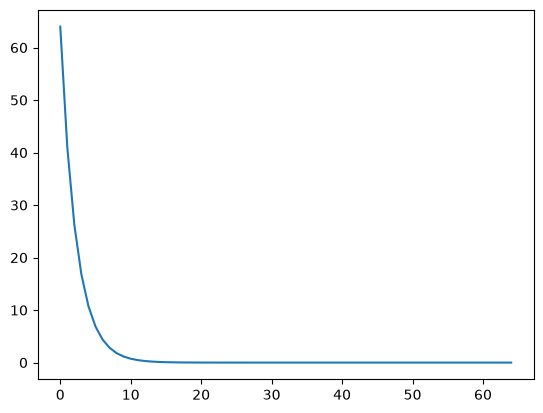

In [54]:
import matplotlib.pyplot as plt

history_loss = []
auto_with_optim(torch.optim.SGD, step=lambda f, _x, _count: history_loss.append(f.item()))

plt.plot(history_loss)
plt.show()